*Mathematical Foundations of Robotics · Chapter 3 — Forward Kinematics*

# 3.1 Link Parameters and Frame Assignment

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/03-forward-kinematics/3.1-link-parameters-and-frame-assignment.ipynb)

Forward kinematics asks one question: given the joint variables of a serial arm, where is its end-effector? The
answer is a product of $4\times4$ transforms, one per link, but the product is only useful if every link
transform is built the same way. The **Denavit–Hartenberg (D-H) convention** achieves this by fixing where a frame
sits on each link, so that four numbers — two describing the link, two describing its connection to the neighbour —
determine the whole transform. This notebook develops the convention in Craig's (modified) form, derives the link
transform, relates it to the standard (Spong) form, turns the frame-assignment recipe into an algorithm that
can be run on a real robot's joint axes, and shows honestly how D-H frames differ from the frames a simulator
attaches to its bodies.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §3.1–3.5 (link description, link connection, affixing frames, the link transformation) |
| **Parallel reading** | Spong et al. Ch. 3 (forward kinematics; the standard D-H convention) · Siciliano et al. Ch. 2 (direct kinematics, D-H convention) · Lynch & Park Ch. 4 and its D-H appendix · Corke *RVC* Ch. 7 |
| **Lectures** | [Lecture 16 — Modelling of manipulating robots using D-H principle I](https://www.youtube.com/watch?v=BHXEw_yf5BY) · [Lecture 17 — Understanding manipulator modelling using D-H principle II](https://www.youtube.com/watch?v=6C7Kcrp6rlg) · [Frame assignment for robotic manipulators (Direct Kinematics I)](https://www.youtube.com/watch?v=fNIyNF87q9I) · [D-H tables (Direct Kinematics II)](https://www.youtube.com/watch?v=DPO9Se6ZqN0) · [Creating transformation matrices from D-H tables (III)](https://www.youtube.com/watch?v=yjLVBbK_rOU) |
| **Prerequisites** | [2.3 Homogeneous Transformations](../02-spatial-descriptions-and-transformations/2.3-homogeneous-transformations.ipynb) |
| **Study time** | about 3 hours |

## Learning objectives

After working through this notebook you should be able to:

1. **Describe** a link by its length $a_{i-1}$ and twist $\alpha_{i-1}$, and the connection of two links by the offset $d_i$ and the joint angle $\theta_i$, and **compute** all four from two joint axes given as lines in space.
2. **Apply** Craig's frame-assignment recipe, including the special cases of intersecting and parallel axes, prismatic joints, and the first and last frames.
3. **Derive** the modified link transform ${}^{i-1}_{i}T = R_X(\alpha_{i-1})\,D_X(a_{i-1})\,R_Z(\theta_i)\,D_Z(d_i)$ as four elementary moves and write it down for $\alpha_{i-1} = 0, \pm 90^\circ$.
4. **State** the standard (distal, Spong) convention and **prove** that its table is the modified table with the $(\alpha, a)$ columns shifted by one row.
5. **Check** a pair of frames against the two D-H rules and **recover** the four parameters from a link transform.
6. **Run** the recipe as an algorithm on the joint axes of a real robot (the UR5e in MuJoCo) and **explain** why the resulting frames differ from the frames of the simulator's bodies.

## Contents

1. [Why a convention is needed](#1.-Why-a-convention-is-needed)
2. [Link description: length and twist](#2.-Link-description:-length-and-twist)
3. [Link connection: offset and joint angle](#3.-Link-connection:-offset-and-joint-angle)
4. [Affixing frames to links: Craig's recipe](#4.-Affixing-frames-to-links:-Craig's-recipe)
5. [The link transformation as four moves](#5.-The-link-transformation-as-four-moves)
6. [Exploring the four parameters](#6.-Exploring-the-four-parameters)
7. [The standard (distal) convention](#7.-The-standard-(distal)-convention)
8. [The recipe as an algorithm, and the D-H rules as a test](#8.-The-recipe-as-an-algorithm,-and-the-D-H-rules-as-a-test)
9. [A real robot: the UR5e's joint axes](#9.-A-real-robot:-the-UR5e's-joint-axes)
10. [Worked examples](#10.-Worked-examples)
11. [Summary, common mistakes and exercises](#11.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit.transforms import rotx, roty, rotz, make_T, inv_T, transl, is_transform
from rgkit import kinematics as kin, dh_tools as dh, dh_plot as dp
from rgkit.kinematics import dh_modified, dh_standard, fk_dh
import sympy as sp

## 1. Why a convention is needed

A serial arm is a chain of rigid links joined by one-degree-of-freedom joints. Chapter 2 gave us the tool for
describing such a chain: attach a frame $\{i\}$ to every link, write the transform ${}^{i-1}_{i}T$ of each frame
relative to its predecessor, and multiply,

$$
{}^{0}_{N}T(\mathbf q) = {}^{0}_{1}T(q_1)\;{}^{1}_{2}T(q_2)\cdots{}^{N-1}_{N}T(q_N).
$$

Nothing in Chapter 2 says **where** the frames should be put. If every engineer places them freely, then

* every link transform is a general element of $SE(3)$ and needs **six** numbers (three for the orientation, three for
  the position), even though a joint can move in only one way;
* two engineers describing the same arm produce different matrices, and neither can reconstruct the other's from a
  verbal description of the robot;
* the six numbers of a link mix information about the *shape* of the link with information about the *current*
  joint value, so the table cannot be tabulated once and for all.

Figure 1 illustrates the freedom. Both panels show the same planar two-link arm in the same configuration. On the
left the frames follow a systematic rule; on the right they were placed arbitrarily. Both descriptions are
correct, but only the left one can be written down as a short table.

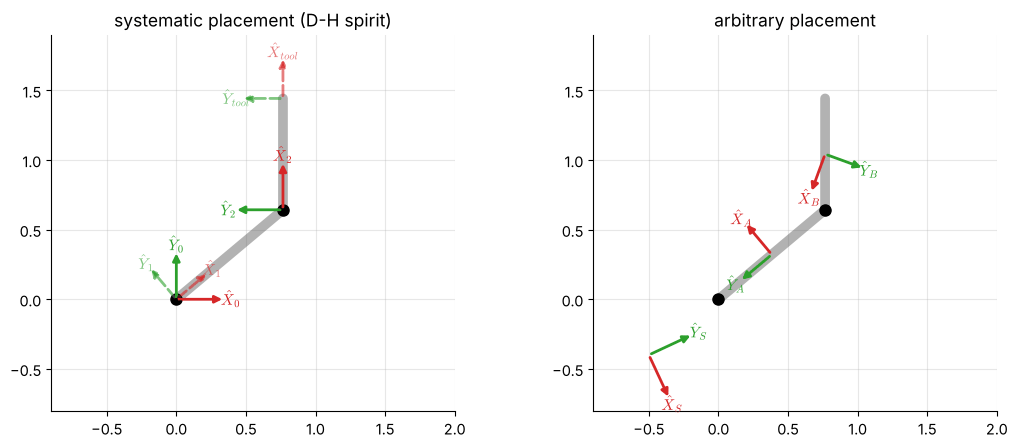

A general link transform has 6 free parameters; a D-H link transform has 4 (one of which is the joint variable).


In [2]:
L1, L2, t1, t2 = 1.0, 0.8, deg(40), deg(50)
p1 = np.array([L1 * np.cos(t1), L1 * np.sin(t1)])
p2 = p1 + L2 * np.array([np.cos(t1 + t2), np.sin(t1 + t2)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, title in zip(axes, ["systematic placement (D-H spirit)", "arbitrary placement"]):
    ax.plot([0, p1[0], p2[0]], [0, p1[1], p2[1]], "-", color="#555", lw=7, solid_capstyle="round", alpha=0.45)
    ax.plot([0, p1[0]], [0, p1[1]], "ko", ms=8)
    ax.set_aspect("equal"); ax.set_xlim(-0.9, 2.0); ax.set_ylim(-0.8, 1.9); ax.set_title(title)
# left: X axes along the links, origins on the joint axes
draw_frame_2d(axes[0], 0, (0, 0), "0", length=0.35)
draw_frame_2d(axes[0], t1, (0, 0), "1", length=0.3, ls="--", alpha=0.6)
draw_frame_2d(axes[0], t1 + t2, p1, "2", length=0.35)
draw_frame_2d(axes[0], t1 + t2, p2, "tool", length=0.3, ls="--", alpha=0.6)
# right: base rotated and shifted, link frames at mid-links with X perpendicular to the link
draw_frame_2d(axes[1], deg(-65), (-0.5, -0.4), "S", length=0.35)
draw_frame_2d(axes[1], t1 + deg(90), 0.5 * p1, "A", length=0.3)
draw_frame_2d(axes[1], t1 + t2 + deg(160), 0.5 * (p1 + p2), "B", length=0.3)
plt.tight_layout(); plt.show()
print("A general link transform has", 3 + 3, "free parameters; a D-H link transform has", 4, "(one of which is the joint variable).")

*Figure 1 — the same arm with systematic frames (left) and with arbitrary ones (right).*

The Denavit–Hartenberg convention, published by J. Denavit and R. S. Hartenberg in 1955 for lower-pair
mechanisms, removes the freedom. Because every joint of an industrial arm is a **revolute** or a **prismatic**
joint, a joint can be reduced to a **line in space** — the axis about which the link turns or along which it
slides. A link is then a rigid body that holds two such lines, and *only the relative position of the two lines
matters for the kinematics*: casting shapes, bolt holes and covers are irrelevant. The next two sections show that
the relation between two lines in space needs exactly two numbers, and that locating a link relative to its
neighbour along the shared joint axis needs two more.

## 2. Link description: length and twist

Number the joint axes $1, 2, \dots, N$ from the base. **Link $i-1$** is the rigid body that carries joint axis
$i-1$ at its proximal end and joint axis $i$ at its distal end. Two lines in three-dimensional space are, in general,
**skew**: they neither intersect nor are parallel. There is then exactly one line segment that is perpendicular to
both and has finite length — the **common normal**. Its length and the angle between the lines are the two
numbers we need.

> **Definition (link length and link twist, Craig §3.2).**
> * The **link length** $a_{i-1}$ is the length of the common normal of joint axes $i-1$ and $i$; $a_{i-1}\ge 0$.
> * The **link twist** $\alpha_{i-1}$ is the angle between axis $i-1$ and axis $i$, measured in a plane perpendicular
>   to the common normal, from axis $i-1$ to axis $i$, with the right-hand rule about the direction of the common
>   normal (pointing from axis $i-1$ towards axis $i$).

The index $i-1$ on the length and twist is not an accident: they describe link $i-1$, which lies between axes $i-1$ and
$i$. The convention that this notebook calls **modified** (Craig's) therefore lists $\alpha_{i-1}, a_{i-1}$ in row $i$
of the table, beside $d_i,\theta_i$.

Three special cases occur constantly:

| Relation of axes $i-1$ and $i$ | $a_{i-1}$ | $\alpha_{i-1}$ | common normal |
|:--|:--|:--|:--|
| **intersecting** | $0$ | the angle between them (usually $\pm90^\circ$) | none needed; take $\hat X_{i-1}\perp$ both axes |
| **parallel** | the distance between them | $0$ (or $180^\circ$ if the axes are antiparallel) | not unique — choose one that makes a later offset zero |
| **perpendicular, skew** | the shortest distance | $\pm 90^\circ$ | unique |

The function `common_normal` of `rgkit.dh_tools` returns the feet of the common normal on both lines and
classifies the pair. The cell below measures $a$ and $\alpha$ for two lines chosen so that the answer is known in
advance: axis $i-1$ is the vertical line through the origin, axis $i$ is a line parallel to the $yz$-plane at
$x = 0.4$, tilted by $40^\circ$.

In [3]:
z_prev = np.array([0.0, 0.0, 1.0])                                   # axis i-1: the z axis
p_i    = np.array([0.4, 0.3, 0.2])                                   # axis i passes through this point ...
z_i    = np.array([0.0, -np.sin(deg(40)), np.cos(deg(40))])          # ... in this direction
foot_prev, foot_i, kind = dh.common_normal(np.zeros(3), z_prev, p_i, z_i)
x_dir = (foot_i - foot_prev) / np.linalg.norm(foot_i - foot_prev)    # X_{i-1}: along the common normal
a_len = np.linalg.norm(foot_i - foot_prev)
alpha = np.arctan2(x_dir @ np.cross(z_prev, z_i), z_prev @ z_i)      # angle from axis i-1 to axis i about X_{i-1}
print("kind of pair      :", kind)
print("foot on axis i-1  :", foot_prev.round(4), "   foot on axis i:", foot_i.round(4))
print(f"link length a_(i-1) = {a_len:.4f} m   (expected 0.4)")
print(f"link twist  alpha_(i-1) = {np.degrees(alpha):.2f}°   (expected 40°)")

kind of pair      : skew
foot on axis i-1  : [0.     0.     0.5575]    foot on axis i: [ 0.4    -0.      0.5575]
link length a_(i-1) = 0.4000 m   (expected 0.4)
link twist  alpha_(i-1) = 40.00°   (expected 40°)


## 3. Link connection: offset and joint angle

Neighbouring links $i-1$ and $i$ share the joint axis $i$. Along that axis there are two common normals: $a_{i-1}$,
which arrives from axis $i-1$, and $a_i$, which leaves towards axis $i+1$. Their *relative position* on the
shared axis is described by two numbers (Craig §3.3):

> * The **link offset** $d_i$ is the signed distance along axis $i$ from the point where $a_{i-1}$ meets the axis to
>   the point where $a_i$ meets it.
> * The **joint angle** $\theta_i$ is the angle between the two common normals, measured about axis $i$ from the
>   direction of $a_{i-1}$ to the direction of $a_i$ (right-hand rule about axis $i$).

For a **revolute** joint the link rotates about axis $i$, so $\theta_i$ changes and is the **joint variable**; $d_i$
is a constant. For a **prismatic** joint the link slides along axis $i$, so $d_i$ is the joint variable and $\theta_i$
is a constant. The other three of the four parameters are fixed by the mechanical design.

**The ends of the chain.** Link 0 is the fixed base, and there is no axis $0$ and no axis $N+1$, so $a_0$, $\alpha_0$
and the corresponding data at the far end are not determined by geometry. Craig fixes them by convention: choose
frame $\{0\}$ so that $\{0\}$ and $\{1\}$ coincide when the first joint variable is zero, which gives
$a_0 = \alpha_0 = 0$ and, for a revolute joint 1, $d_1 = 0$. At the far end choose $\{N\}$ so that as many of
$a_N, \alpha_N, d_N, \theta_N$ as possible vanish. (The row $N$ of the table still contains $\alpha_{N-1}, a_{N-1}$ and $d_N,
\theta_N$; what is freely chosen is the *placement* of the last frame on its axis and the direction of $\hat X_N$.)

| Parameter | Axes involved | Measured | Variable for |
|:--|:--|:--|:--|
| $a_{i-1}$ | $i-1,\ i$ | **along** $\hat X_{i-1}$ | — |
| $\alpha_{i-1}$ | $i-1,\ i$ | **about** $\hat X_{i-1}$ | — |
| $d_i$ | normals $a_{i-1},\ a_i$ | **along** $\hat Z_i$ | prismatic joint |
| $\theta_i$ | normals $a_{i-1},\ a_i$ | **about** $\hat Z_i$ | revolute joint |

## 4. Affixing frames to links: Craig's recipe

The four parameters have a geometric meaning even without frames. The convention makes them *computable* by giving
each link a frame that is built from the common normals. For **frame $\{i\}$, attached to link $i$**:

1. **$\hat Z_i$ lies along joint axis $i$.** The joint motion is then always "turn about $\hat Z_i$" or "slide along $\hat Z_i$".
2. **The origin $O_i$ is at the foot of the common normal of axes $i$ and $i+1$, on axis $i$.** If the two axes
   intersect, $O_i$ is their intersection point.
3. **$\hat X_i$ points along the common normal from axis $i$ towards axis $i+1$.** If the axes intersect, $\hat X_i$ is
   perpendicular to the plane containing both, $\hat X_i = \pm\,\hat Z_i\times\hat Z_{i+1}$ (either sign is allowed).
4. **$\hat Y_i = \hat Z_i\times\hat X_i$** completes a right-handed frame.
5. **Ends of the chain.** Choose $\{0\}$ to coincide with $\{1\}$ when $q_1 = 0$; choose $\{N\}$ (origin on axis $N$,
   $\hat X_N$ free) to make as many parameters as possible zero.

When axes $i$ and $i+1$ are **parallel** there are infinitely many common normals; take the one that passes through the
point where the previous normal $a_{i-1}$ arrives, so that $d_i = 0$. For a **prismatic** joint the direction of
$\hat Z_i$ is the sliding direction, but the axis has no position; place the origin wherever it makes parameters
vanish (typically so that $d_i = 0$ at the start of the stroke).

In terms of the frames the four parameters read (Craig §3.4):

$$
\begin{aligned}
a_{i-1} &= \text{distance from } \hat Z_{i-1} \text{ to } \hat Z_i \text{ measured along } \hat X_{i-1},\\
\alpha_{i-1} &= \text{angle from } \hat Z_{i-1} \text{ to } \hat Z_i \text{ measured about } \hat X_{i-1},\\
d_i &= \text{distance from } \hat X_{i-1} \text{ to } \hat X_i \text{ measured along } \hat Z_i,\\
\theta_i &= \text{angle from } \hat X_{i-1} \text{ to } \hat X_i \text{ measured about } \hat Z_i .
\end{aligned}
$$

Two things are worth stating explicitly because they are the sources of most mistakes.

* **Frames are not unique.** The sign of $\hat Z_i$ (the direction in which positive joint motion is counted), the sign of
  $\hat X_i$ for intersecting axes and the common normal for parallel axes are all free. Different but equally valid
  choices give different tables for the same robot.
* **The frame is on the near joint.** In Craig's convention frame $\{i\}$ sits on axis $i$, at the *proximal* end of
  link $i$. (The standard convention of Section 7 puts frame $\{i\}$ at the distal end.)

**A worked picture.** Consider the *articulated* (elbow) arm: a vertical waist axis, then two parallel horizontal
axes for the shoulder and the elbow. Axes 1 and 2 intersect and are perpendicular; axes 2 and 3 are parallel and
separated by the upper-arm length $L_2$. The recipe gives

| $i$ | $\alpha_{i-1}$ | $a_{i-1}$ | $d_i$ | $\theta_i$ |
|:--|:--|:--|:--|:--|
| 1 | $0$ | $0$ | $0$ | $\theta_1$ |
| 2 | $90^\circ$ | $0$ | $0$ | $\theta_2$ |
| 3 | $0$ | $L_2$ | $0$ | $\theta_3$ |

plus a fixed tool offset $D_X(L_3)$ along $\hat X_3$ to reach the hand. Figure 2 draws these frames (small arrows; the dotted
lines are the joint axes). Row 2 is $90^\circ$ because $\hat Z_2$ is obtained from $\hat Z_1$ by a quarter turn about $\hat X_1$;
row 3 has $\alpha_2 = 0$ because $\hat Z_3\parallel\hat Z_2$.

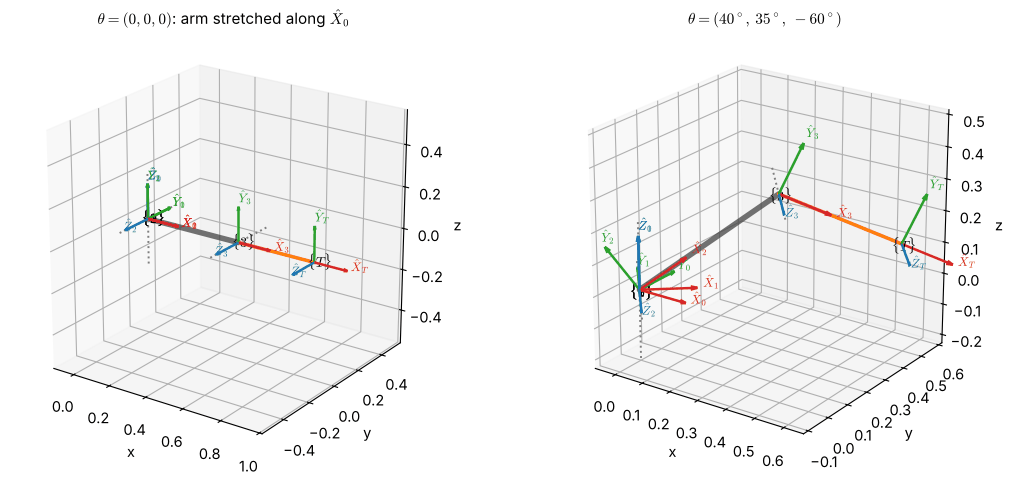

In [4]:
L2_, L3_ = 0.5, 0.4
artic = [(0, 0, 0, 0, "R"), (deg(90), 0, 0, 0, "R"), (0, L2_, 0, 0, "R")]
fig = plt.figure(figsize=(11, 5))
for k, (q, title) in enumerate([([0, 0, 0], r"$\theta=(0,0,0)$: arm stretched along $\hat X_0$"),
                                 ([deg(40), deg(35), deg(-60)], r"$\theta=(40^\circ,\,35^\circ,\,-60^\circ)$")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    Ts = dp.draw_arm(ax, artic, q, "modified", frame_length=0.17, T_tool=transl(L3_, 0, 0), axis_length=0.22)
    dp.equal_limits(ax, ax._dh_points, 0.25)
    ax.view_init(22, -55); ax.set_title(title, fontsize=11)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

*Figure 2 — frames assigned by the recipe to the articulated arm, at the zero configuration and at a general one.
The thick grey polyline is the chain of common normals and offsets; the orange segment is the fixed tool offset
$D_X(L_3)$; the dotted lines are the joint axes.*

## 5. The link transformation as four moves

To obtain ${}^{i-1}_{i}T$ we must carry frame $\{i-1\}$ onto frame $\{i\}$. Because of the way the frames were
built, this takes exactly four elementary moves, each about or along **one axis of the current frame** and each
involving one of the four parameters. Three intermediate frames $\{R\}$, $\{Q\}$, $\{P\}$ record the progress:

1. **Rotate** by $\alpha_{i-1}$ about $\hat X_{i-1}$. Frame $\{R\}$ has the same origin as $\{i-1\}$, and $\hat Z_R$ is now parallel to joint axis $i$.
2. **Translate** by $a_{i-1}$ along $\hat X_R$. Frame $\{Q\}$ has its origin on joint axis $i$, at the foot of the common normal.
3. **Rotate** by $\theta_i$ about $\hat Z_Q$. Frame $\{P\}$ has $\hat X_P$ pointing along the next common normal, $\hat X_i$.
4. **Translate** by $d_i$ along $\hat Z_P$. The origin has slid along axis $i$ to $O_i$; frame $\{P\}$ has become $\{i\}$.

Each move is described in the **current** frame, so the transforms **post-multiply** (Section 2.2 of this course):

$$
{}^{i-1}_{i}T = {}^{i-1}_{R}T\;{}^{R}_{Q}T\;{}^{Q}_{P}T\;{}^{P}_{i}T = R_X(\alpha_{i-1})\,D_X(a_{i-1})\,R_Z(\theta_i)\,D_Z(d_i).
$$

Figure 3 shows the four moves for one link; the animation below it plays them in sequence. (In the saved notebook
the animation appears as four key frames; run the cell yourself to play it.)

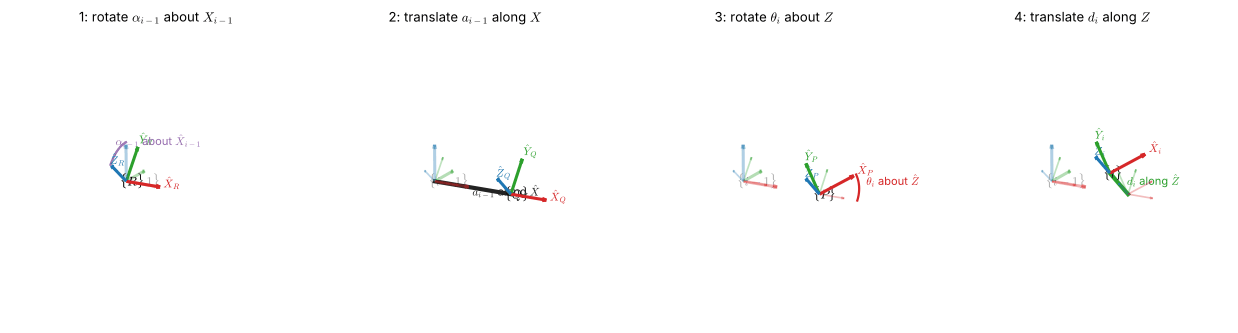

In [5]:
al, a_, d_, th = deg(50), 1.0, 0.6, deg(40)
fig = plt.figure(figsize=(12.5, 3.6))
titles = ["1: rotate $\\alpha_{i-1}$ about $X_{i-1}$", "2: translate $a_{i-1}$ along $X$", "3: rotate $\\theta_i$ about $Z$", "4: translate $d_i$ along $Z$"]
for k in range(4):
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    dp.draw_dh_step(ax, k + 1, al, a_, d_, th, length=1.0, fontsize=8)
    ax.view_init(18, -62); ax.set_title(titles[k], fontsize=9.5)
plt.tight_layout(); plt.show()

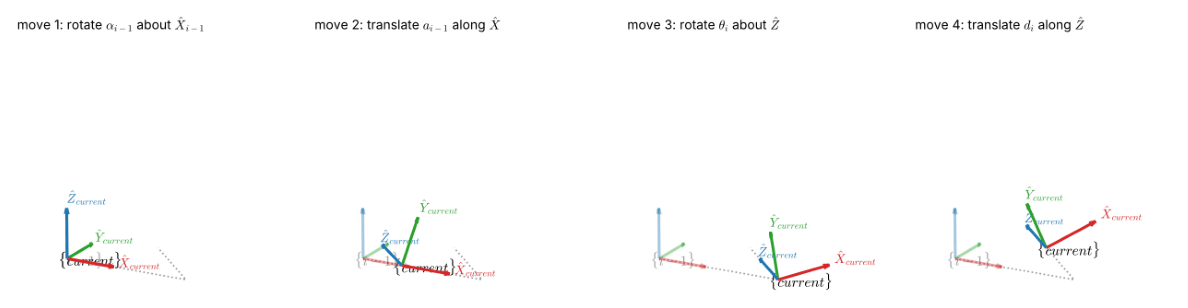

In [6]:
steps = [lambda f: make_T(rotx(f * al)), lambda f: transl(f * a_, 0, 0), lambda f: make_T(rotz(f * th)), lambda f: transl(0, 0, f * d_)]
labels = [r"rotate $\alpha_{i-1}$ about $\hat X_{i-1}$", r"translate $a_{i-1}$ along $\hat X$", r"rotate $\theta_i$ about $\hat Z$", r"translate $d_i$ along $\hat Z$"]

def pose_at(s):
    stage, f = (3, 1.0) if s >= 4 else (int(s), s - int(s))
    T = np.eye(4)
    for k in range(stage):
        T = T @ steps[k](1.0)
    return T @ steps[stage](f), stage

fig = plt.figure(figsize=(5.4, 5.2))
ax = fig.add_subplot(111, projection="3d")
trail = np.array([pose_at(s)[0][:3, 3] for s in np.linspace(0, 4, 81)])

def update(s):
    ax.cla()
    T, stage = pose_at(s)
    draw_frame(ax, np.eye(4), name="i-1", length=0.4, alpha=0.4, label_axes=False)
    draw_frame(ax, T, name="current", length=0.4)
    ax.plot(*trail.T, color="#999", ls=":", lw=1.2)
    ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.9, 0.6); ax.set_zlim(-0.3, 1.2); ax.set_box_aspect((1.8, 1.5, 1.5))
    ax.view_init(18, -62); ax.set_axis_off()
    ax.set_title(f"move {stage + 1}: " + labels[stage], fontsize=10)

animate(fig, update, np.linspace(0, 4, 49), interval=90, gif="assets/3.1-four-moves.gif")

**Multiplying out.** Write $c\alpha = \cos\alpha_{i-1}$, $s\alpha = \sin\alpha_{i-1}$, $c\theta = \cos\theta_i$,
$s\theta = \sin\theta_i$. The product of the four elementary $4\times4$ matrices is computed below symbolically, so
that the result can be compared term by term with Craig's equation 3.6.

In [7]:
ca, sa, ct, st, a, d = sp.symbols(r"c\alpha_{i-1} s\alpha_{i-1} c\theta_{i} s\theta_{i} a_{i-1} d_{i}")
Rx_ = sp.Matrix([[1, 0, 0, 0], [0, ca, -sa, 0], [0, sa, ca, 0], [0, 0, 0, 1]])
Dx_ = sp.Matrix([[1, 0, 0, a], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
Rz_ = sp.Matrix([[ct, -st, 0, 0], [st, ct, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
Dz_ = sp.Matrix([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, d], [0, 0, 0, 1]])
T_link = (Rx_ * Dx_ * Rz_ * Dz_).applyfunc(sp.expand)
display(Math(r"R_X(\alpha_{i-1})\,D_X(a_{i-1})\,R_Z(\theta_i)\,D_Z(d_i) \;=\; " + sp.latex(T_link)))

# the same matrix, evaluated numerically, equals the library's link transform
vals = {ca: np.cos(deg(30)), sa: np.sin(deg(30)), ct: np.cos(deg(-20)), st: np.sin(deg(-20)), a: 0.4, d: 0.25}
print("matches rgkit.kinematics.dh_modified:",
      np.allclose(np.array(T_link.subs(vals), dtype=float), dh_modified(deg(30), 0.4, 0.25, deg(-20))))

<IPython.core.display.Math object>

matches rgkit.kinematics.dh_modified: True


> **Link transformation, modified (Craig) convention — Craig eq. 3.6.**
> $$
> {}^{i-1}_{i}T=\begin{bmatrix}
> c\theta_i & -s\theta_i & 0 & a_{i-1}\\
> s\theta_i\,c\alpha_{i-1} & c\theta_i\,c\alpha_{i-1} & -s\alpha_{i-1} & -s\alpha_{i-1}\,d_i\\
> s\theta_i\,s\alpha_{i-1} & c\theta_i\,s\alpha_{i-1} & c\alpha_{i-1} & c\alpha_{i-1}\,d_i\\
> 0&0&0&1\end{bmatrix}
> $$

Because two of the four angles of interest are almost always $0$ or $\pm 90^\circ$, three special cases deserve to be
known by heart:

| $\alpha_{i-1}$ | ${}^{i-1}_{i}T$ |
|:--|:--|
| $0$ | $\begin{bmatrix}c\theta&-s\theta&0&a\\ s\theta&c\theta&0&0\\0&0&1&d\\0&0&0&1\end{bmatrix}$ — a plain rotation about $\hat Z$ with the offsets $(a,0,d)$ |
| $+90^\circ$ | $\begin{bmatrix}c\theta&-s\theta&0&a\\0&0&-1&-d\\ s\theta&c\theta&0&0\\0&0&0&1\end{bmatrix}$ |
| $-90^\circ$ | $\begin{bmatrix}c\theta&-s\theta&0&a\\0&0&1&d\\ -s\theta&-c\theta&0&0\\0&0&0&1\end{bmatrix}$ |

**Reading the matrix.** Its last column is $\big(a_{i-1},\ -s\alpha_{i-1}d_i,\ c\alpha_{i-1}d_i\big)^{\mathsf T}= a_{i-1}\hat X_{i-1}+d_i\hat Z_i$,
in frame $\{i-1\}$: the origin of $\{i\}$ is reached by going $a_{i-1}$ along $\hat X_{i-1}$ and then $d_i$ along
$\hat Z_i$ — which is the definition of the two lengths. Its third column, $(0,-s\alpha_{i-1},c\alpha_{i-1})^{\mathsf T}$, is
$\hat Z_i$ in $\{i-1\}$: it has no $x$ component because $\hat Z_i\perp\hat X_{i-1}$ — the first **D-H rule**. The two
rules, which every correctly assigned pair of frames obeys, are therefore:

> **D-H rules (modified convention).** (i) $\hat X_{i-1}\perp\hat Z_i$; (ii) $\hat X_{i-1}$ **intersects** $\hat Z_i$.

These two rules are exactly what removes two of the six degrees of freedom of a general transform. We use them as a
test in Section 8.

## 6. Exploring the four parameters

The explorer below draws one link for any values of $(\alpha_{i-1}, a_{i-1}, d_i, \theta_i)$, together with the
resulting matrix. Move the sliders and watch which feature of the picture each parameter controls: $\alpha$ tilts axis
$i$ about $\hat X_{i-1}$, $a$ stretches the common normal, $\theta$ turns $\hat X_i$ about axis $i$, and $d$ slides
frame $\{i\}$ along axis $i$. (In the saved notebook the explorer shows its default setting.)

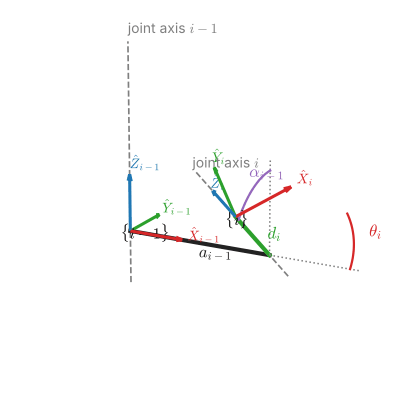

<IPython.core.display.Math object>

In [8]:
def link_explorer(alpha_deg=50, a=1.0, d=0.6, theta_deg=40, intermediate=False):
    fig = plt.figure(figsize=(6.6, 5.2))
    ax = fig.add_subplot(111, projection="3d")
    T = dp.draw_dh_link(ax, deg(alpha_deg), a, d, deg(theta_deg), show_intermediate=intermediate)
    ax.view_init(18, -62); ax.set_box_aspect((1, 1, 1), zoom=1.35)
    plt.show()
    display(Math(matrix_to_latex(T, 3, r"{}^{i-1}_{i}T")))

interact(link_explorer,
         alpha_deg=widgets.FloatSlider(50, min=-180, max=180, step=5, description="α (°)"),
         a=widgets.FloatSlider(1.0, min=0.0, max=1.5, step=0.05, description="a"),
         d=widgets.FloatSlider(0.6, min=-1.0, max=1.0, step=0.05, description="d"),
         theta_deg=widgets.FloatSlider(40, min=-180, max=180, step=5, description="θ (°)"),
         intermediate=widgets.Checkbox(False, description="show {R},{Q},{P}"));

*Figure 4 — a single link: the common normal $a_{i-1}$ (black), the offset $d_i$ (green) along axis $i$, the twist
$\alpha_{i-1}$ (purple) and the joint angle $\theta_i$ (red). The dotted grey lines at the foot of the common normal
are parallel copies of $\hat Z_{i-1}$ and $\hat X_{i-1}$ against which the two angles are measured.*

## 7. The standard (distal) convention

Many textbooks — Spong et al., Siciliano et al., Corke's toolbox — use a different version of the same idea, usually
called the **standard** or **distal** convention. It differs in two respects.

* **Frame placement.** Frame $\{i\}$ is attached to the **far** end of link $i$ and has $\hat Z_i$ along joint axis
  **$i+1$**; the joint-$i$ motion is a rotation about (or a slide along) $\hat Z_{i-1}$. Its origin $O_i$ is where the common
  normal of axes $i$ and $i+1$ meets axis $i+1$.
* **Order of the moves.** The link transform is $A_i = R_Z(\theta_i)\,D_Z(d_i)\,D_X(a_i)\,R_X(\alpha_i)$ and the
  table is headed $\theta_i, d_i, a_i, \alpha_i$ — the *distal* length and twist $a_i,\alpha_i$ appear in row $i$.

$$
A_i = {}^{i-1}_{i}T_{\text{std}} = \begin{bmatrix}
c\theta_i & -s\theta_i c\alpha_i & s\theta_i s\alpha_i & a_i c\theta_i\\
s\theta_i & c\theta_i c\alpha_i & -c\theta_i s\alpha_i & a_i s\theta_i\\
0 & s\alpha_i & c\alpha_i & d_i\\ 0&0&0&1\end{bmatrix}.
$$

| | **Modified** (Craig; this course) | **Standard** (Spong, Siciliano, Corke) |
|:--|:--|:--|
| frame $\{i\}$ sits | on axis $i$, near end of link $i$ | on axis $i+1$, far end of link $i$ |
| table columns | $\alpha_{i-1},\ a_{i-1},\ d_i,\ \theta_i$ | $\theta_i,\ d_i,\ a_i,\ \alpha_i$ |
| link transform | $R_X(\alpha_{i-1})D_X(a_{i-1})R_Z(\theta_i)D_Z(d_i)$ | $R_Z(\theta_i)D_Z(d_i)D_X(a_i)R_X(\alpha_i)$ |
| joint $i$ moves along / about | $\hat Z_i$ | $\hat Z_{i-1}$ |
| last column of $T$ | $[a_{i-1},\,-s\alpha_{i-1}d_i,\,c\alpha_{i-1}d_i]^{\mathsf T}$ | $[a_ic\theta_i,\ a_is\theta_i,\ d_i]^{\mathsf T}$ |

The two conventions describe the same robots; **the numbers in the two tables are closely related.** A translation
along $\hat X$ and a rotation about $\hat X$ **commute**, so $R_X(\alpha)D_X(a)=D_X(a)R_X(\alpha)$. Write the
modified chain with this freedom:

$$
\prod_{i=1}^{N} R_X(\alpha_{i-1})D_X(a_{i-1})\,R_Z(\theta_i)D_Z(d_i)
= \big[R_X(\alpha_0)D_X(a_0)\big]\prod_{i=1}^{N}\Big( R_Z(\theta_i)D_Z(d_i)\,\underbrace{R_X(\alpha_{i})D_X(a_{i})}_{=\,D_X(a_i)R_X(\alpha_i)}\Big)\Big[R_X(\alpha_N)D_X(a_N)\Big]^{-1},
$$

where the factors $R_X(\alpha_i)D_X(a_i)$ for $i=1,\dots,N-1$ have simply been *moved one place to the left*, from the start
of row $i+1$ to the end of row $i$. This proves

> **Theorem (row shift).** If $\alpha_0=a_0=0$, the standard table with rows $(\theta_i,\ d_i,\ a_i,\ \alpha_i)$ and the
> modified table with rows $(\alpha_{i-1},\ a_{i-1},\ d_i,\ \theta_i)$ contain the **same** numbers: the standard
> row $i$ takes $(d_i,\theta_i)$ from modified row $i$ and $(a_i,\alpha_i)$ from modified row $i+1$ (and the pair
> $(a_N,\alpha_N)$ is the fixed tool transform of the last frame). The two products are then identical:
> ${}^{0}_{N}T_{\text{mod}}={}^{0}_{N}T_{\text{std}}$.

The frames in between are *not* the same — the standard frame $\{i\}$ equals the modified frame $\{i\}$ advanced by
the distal link transform $R_X(\alpha_i)D_X(a_i)$ — but the end-effector pose is. This is why published tables for
the same robot look so similar and why mixing conventions silently produces wrong answers: **a table is only
meaningful together with the name of its convention.** The cell below verifies the theorem on random tables with
prismatic and revolute joints, and Figure 5 draws both sets of frames on the articulated arm.

largest difference between the end poses of 200 random modified/standard table pairs: 8.9e-16

Articulated arm, modified rows (alpha_{i-1}, a_{i-1}, d_i, theta_i):
    [0. 0. 0. 0.]
    [90.  0.  0.  0.]
    [0.  0.5 0.  0. ]
Articulated arm, standard rows (alpha_i, a_i, d_i, theta_i) — the (alpha, a) columns moved up one row:
    [90.  0.  0.  0.]
    [0.  0.5 0.  0. ]
    [0.  0.4 0.  0. ]


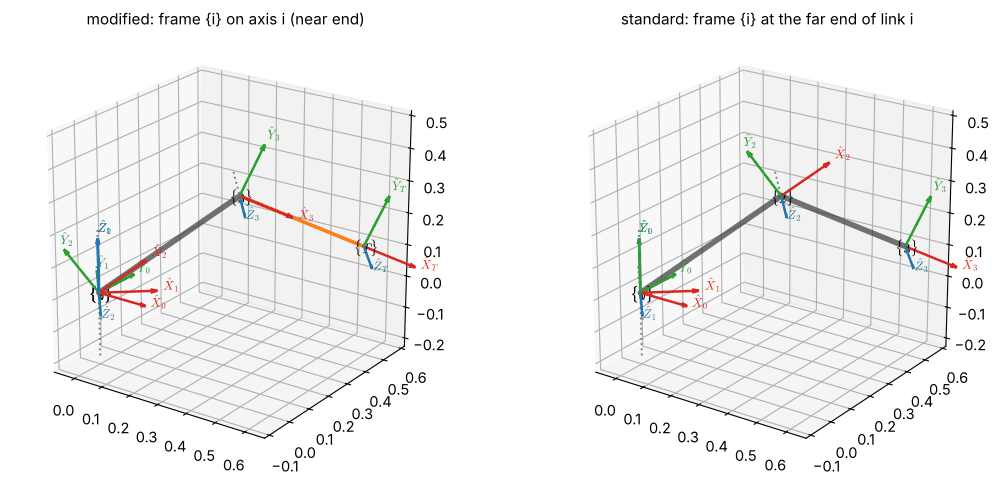

In [9]:
rng = np.random.default_rng(3)
worst = 0.0
for trial in range(200):
    n = rng.integers(2, 8)
    kinds = rng.choice(["R", "P"], n)
    mod = [(rng.uniform(-np.pi, np.pi), rng.uniform(0, 0.6), rng.uniform(-0.5, 0.5), rng.uniform(-3, 3), k) for k in kinds]
    mod[0] = (0.0, 0.0) + mod[0][2:]                                    # alpha_0 = a_0 = 0
    std = dh.modified_to_standard(mod)                                  # shift the (alpha, a) columns up one row
    q = rng.uniform(-2, 2, n)
    worst = max(worst, np.abs(fk_dh(mod, q, "modified")[-1] - fk_dh(std, q, "standard")[-1]).max())
print(f"largest difference between the end poses of 200 random modified/standard table pairs: {worst:.1e}")

std_artic = dh.modified_to_standard(artic, tool_alpha=0, tool_a=L3_)
print("\nArticulated arm, modified rows (alpha_{i-1}, a_{i-1}, d_i, theta_i):")
for r in artic: print("   ", np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 3))
print("Articulated arm, standard rows (alpha_i, a_i, d_i, theta_i) — the (alpha, a) columns moved up one row:")
for r in std_artic: print("   ", np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 3))

q = [deg(40), deg(35), deg(-60)]
fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
dp.draw_arm(ax, artic, q, "modified", frame_length=0.17, T_tool=transl(L3_, 0, 0), axis_length=0.2)
dp.equal_limits(ax, ax._dh_points, 0.25); ax.view_init(22, -55); ax.set_title("modified: frame {i} on axis i (near end)", fontsize=11)
ax = fig.add_subplot(1, 2, 2, projection="3d")
dp.draw_arm(ax, std_artic, q, "standard", frame_length=0.17, axis_length=0.2)
dp.equal_limits(ax, ax._dh_points, 0.25); ax.view_init(22, -55); ax.set_title("standard: frame {i} at the far end of link i", fontsize=11)
plt.tight_layout(); plt.show()

*Figure 5 — the same arm at the same joint values with the two sets of frames. In the standard drawing frame
$\{3\}$ sits at the tip of the forearm (the end of the last link) and frames $\{1\}$, $\{2\}$ sit at the far end of the
waist and upper-arm links. The tool point is the same in both.*

**Which should I use?** This course (and Craig's text, and the examination papers) use the modified convention, and
that convention is used throughout this chapter. When a book or a robot manufacturer gives a D-H table, read the
column headings: a table headed $\theta_i, d_i, a_i, \alpha_i$ is standard, and one headed $\alpha_{i-1}, a_{i-1}, d_i, \theta_i$ is modified.
The Row-shift theorem lets you translate between them; the function `modified_to_standard` of `rgkit.dh_tools` does so.

## 8. The recipe as an algorithm, and the D-H rules as a test

Section 4 is a procedure, and a procedure can be programmed. `rgkit.dh_tools.dh_from_axes` takes the joint axes of a
robot — each as a point on the axis and a direction, at one reference configuration — applies the recipe, and
returns both the table and the frames. It is useful in three ways: it checks a hand-made table, it produces a table
when the robot's geometry is only available as numbers (as it is for a simulator model), and it shows
concretely what "non-unique" means.

The D-H rules are a test: given two frames, `dh_violations` returns how far they are from obeying rule (i)
(perpendicularity) and rule (ii) (intersection, measured as the distance between the lines $X_{i-1}$ and $Z_i$).
`dh_params_modified` extracts the four parameters and refuses frames that break the rules.

In [10]:
# joint axes of the articulated arm of Figure 2 at q = 0 (point on the axis, direction)
points     = [[0, 0, 0], [0, 0, 0], [L2_, 0, 0]]
directions = [[0, 0, 1], [0, -1, 0], [0, -1, 0]]
table, frames = dh.dh_from_axes(points, directions, "modified")
print("table found by the algorithm (alpha_{i-1} [deg], a_{i-1}, d_i, theta_i [deg]):")
for r in table: print("   ", np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 4))
print("same as the hand-made table of Section 4:", np.allclose([r[:4] for r in table], [r[:4] for r in artic]))

# rule check on a pair of frames: a correct one, and one whose origin was moved off the axis
T_ok  = dh_modified(deg(60), 0.3, 0.2, deg(25))
T_bad = T_ok.copy(); T_bad[:3, 3] += [0.0, 0.1, 0.0]
print("\nrule violations (perpendicularity, distance between lines X_{i-1} and Z_i):")
print("  valid pair  :", np.round(dh.dh_violations(T_ok), 6))
print("  moved origin:", np.round(dh.dh_violations(T_bad), 6))
try:
    dh.dh_params_modified(T_bad)
except ValueError as e:
    print("  dh_params_modified refuses it:", e)
print("  and recovers the parameters of the valid pair:", np.round(dh.dh_params_modified(T_ok), 4), "= (60°, 0.3, 0.2, 25°) in rad")

table found by the algorithm (alpha_{i-1} [deg], a_{i-1}, d_i, theta_i [deg]):
    [-0.  0.  0. -0.]
    [90.  0.  0. -0.]
    [-0.   0.5  0.  -0. ]
same as the hand-made table of Section 4: True

rule violations (perpendicularity, distance between lines X_{i-1} and Z_i):
  valid pair  : [0. 0.]
  moved origin: [0.   0.05]
  dh_params_modified refuses it: transform is not of modified D-H form: the frames violate the D-H rules
  and recovers the parameters of the valid pair: [1.0472 0.3    0.2    0.4363] = (60°, 0.3, 0.2, 25°) in rad


**Non-uniqueness, concretely.** The frames of Figure 2 were obtained with the sign choice "$\hat X_i$ points from
axis $i$ to axis $i+1$", which makes every $a_i\ge0$. Reversing a single $\hat X_i$ is just as legal: it changes
$a_i\to -a_i$ (a negative link length is allowed in a *table*, even though a physical length is not), shifts the
neighbouring joint offset by $180^\circ$ and leaves the robot unchanged. The next cell takes a planar chain
that folds back on itself — link 1 points along $-x$, link 2 points back along $+x$ — and compares the two sign
policies of `dh_from_axes`.

In [11]:
pts = [[0, 0, 0], [-0.5, 0, 0], [-0.1, 0, 0]]          # three parallel vertical axes at x = 0, -0.5, -0.1
dirs = [[0, 0, 1]] * 3
tab_c, fr_c = dh.dh_from_axes(pts, dirs, "modified", x_sign="craig")
tab_k, fr_k = dh.dh_from_axes(pts, dirs, "modified", x_sign="continuous", x_hint=(-1, 0, 0))
for name, tab in (("craig (every a >= 0)", tab_c), ("continuous (no offsets)", tab_k)):
    print(f"{name:26s} rows (alpha, a, d, theta [deg]):", [tuple(np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 3)) for r in tab])
rng = np.random.default_rng(1)
rel = []
for _ in range(3):
    q = rng.uniform(-3, 3, 3)
    A = fr_c[0] @ fk_dh(tab_c, q)[-1]; B = fr_k[0] @ fk_dh(tab_k, q)[-1]
    assert np.allclose(A[:3, 3], B[:3, 3])
    rel.append(inv_T(A) @ B)
print("\nthe last frames are at the same position for random q; they differ only by the constant rotation",
      np.degrees(np.arctan2(rel[0][1, 0], rel[0][0, 0])).round(1), "° about Z:", all(np.allclose(r, rel[0]) for r in rel))

craig (every a >= 0)       rows (alpha, a, d, theta [deg]): [(np.float64(-0.0), np.float64(0.0), np.float64(0.0), np.float64(-0.0)), (np.float64(-0.0), np.float64(0.5), np.float64(0.0), np.float64(-180.0)), (np.float64(-0.0), np.float64(0.4), np.float64(0.0), np.float64(-0.0))]
continuous (no offsets)    rows (alpha, a, d, theta [deg]): [(np.float64(-0.0), np.float64(0.0), np.float64(0.0), np.float64(-0.0)), (np.float64(-0.0), np.float64(0.5), np.float64(0.0), np.float64(-0.0)), (np.float64(-0.0), np.float64(-0.4), np.float64(0.0), np.float64(-0.0))]

the last frames are at the same position for random q; they differ only by the constant rotation 180.0 ° about Z: True


The two tables are both correct. In the *Craig* policy every link length is non-negative and the joint angle carries an offset of
$180^\circ$ where the arm folds back; in the *continuous* policy the offset vanishes but one length $a_{i-1}$ is negative. The two end frames
are in the same place and differ by a constant rotation because $\hat X_N$ points the other way. Manufacturers' tables (for example those of
Universal Robots) usually follow the second policy. Which table is "right" is a matter of taste — both give the same forward kinematics
up to the orientation convention of the last frame — but a **joint offset**
(a non-zero constant in the $\theta_i$ column, written $\theta_i+\theta_{i0}$ in the table) must be taken into account
whenever joint values from a controller are inserted into the table.

## 9. A real robot: the UR5e's joint axes

A table is a *model* of an arm. We now apply the recipe to a real one: the Universal Robots **UR5e** from
[MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie) (downloaded on first use; see
[docs/MUJOCO.md](../../docs/MUJOCO.md)). A MuJoCo model is a tree of **bodies**; each body has a pose relative to its
parent (`body_pos`, `body_quat`) and may carry a **joint** whose axis (`jnt_axis`) and anchor (`jnt_pos`) are given in
the *body's own frame*. After `mj_kinematics`, `data.xanchor` and `data.xaxis` give, for every joint, a point on its
axis and the direction of the axis in the world frame — precisely the "lines in space" that the recipe needs.

We put the arm in its **zero configuration** ($q=0$, which for the UR5e is the arm stretched out horizontally), read the six
axes, and let the algorithm assign frames. The MuJoCo bodies carry frames of their own, which were drawn by the model's
author (compare the red–green–blue frames in the left image with the D-H frames in the right plot).

In [12]:
from rgkit import robots, mujoco_utils as mju
import mujoco
print(robots.describe("ur5e"))
model, data = robots.load_robot("ur5e", scene="bare")
data.qpos[:] = 0.0                                   # the zero configuration: the arm is stretched out
mujoco.mj_forward(model, data)

pts, dirs, kinds = dh.joint_axes_from_mujoco(model, data)
site = data.site("attachment_site")
print("\njoint axes in the world frame at q = 0 (anchor point, direction):")
for j in range(6):
    print(f"  {model.joint(j).name:20s} point {pts[j].round(3)}  axis {dirs[j].round(3)}")

table_ur, frames_ur = dh.dh_from_axes(pts, dirs, "modified", kinds, tool_point=site.xpos, x_sign="continuous")
print("\nmodified D-H table found by the recipe (alpha_{i-1} [deg], a_{i-1} [m], d_i [m], theta_i-offset [deg]):")
for i, r in enumerate(table_ur, 1):
    print(f"  {i}:", np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 3))

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)



joint axes in the world frame at q = 0 (anchor point, direction):
  shoulder_pan_joint   point [0.    0.    0.163]  axis [0. 0. 1.]
  shoulder_lift_joint  point [ 0.    -0.138  0.163]  axis [ 0. -1.  0.]
  elbow_joint          point [-0.425 -0.007  0.163]  axis [ 0. -1.  0.]
  wrist_1_joint        point [-0.817 -0.007  0.163]  axis [ 0. -1.  0.]
  wrist_2_joint        point [-0.817 -0.134  0.163]  axis [ 0.  0. -1.]
  wrist_3_joint        point [-0.817 -0.134  0.063]  axis [ 0. -1.  0.]

modified D-H table found by the recipe (alpha_{i-1} [deg], a_{i-1} [m], d_i [m], theta_i-offset [deg]):
  1: [-0.  0.  0. -0.]
  2: [90.  0.  0. -0.]
  3: [-0.    -0.425  0.    -0.   ]
  4: [-0.    -0.392  0.134 -0.   ]
  5: [90.   0.   0.1 -0. ]
  6: [-90.    0.    0.1  -0. ]


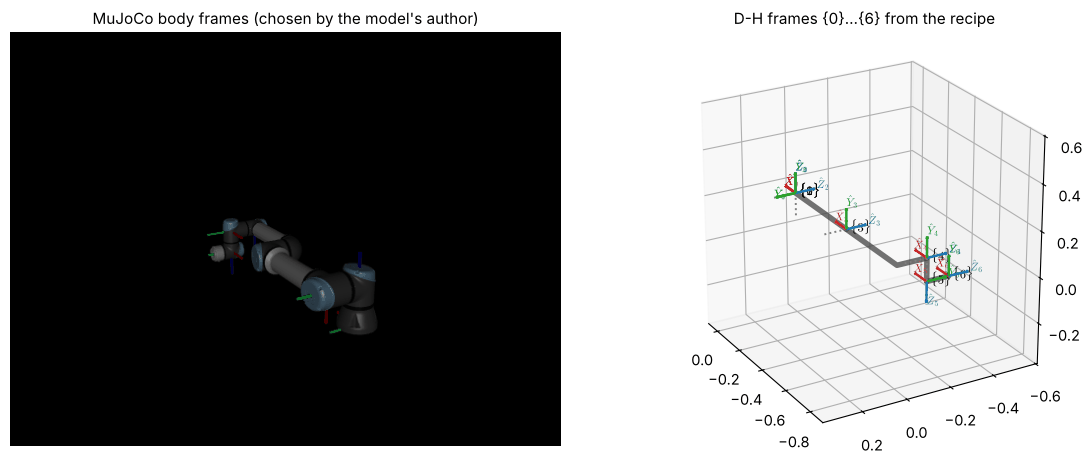

In [13]:
opt = robots.frames_option(model, length=0.12, width=0.006)                   # draws the frame of every body
img = mju.render(model, data, camera=dict(azimuth=150, elevation=-18, distance=2.0, lookat=(-0.35, -0.1, 0.25)),
                 width=560, height=420, scene_option=opt)
fig = plt.figure(figsize=(12, 4.8))
ax0 = fig.add_subplot(1, 2, 1); ax0.imshow(img); ax0.set_axis_off()
ax0.set_title("MuJoCo body frames (chosen by the model's author)", fontsize=11)
ax = fig.add_subplot(1, 2, 2, projection="3d")
Ts = dp.draw_arm(ax, table_ur, np.zeros(6), "modified", base=frames_ur[0], frame_length=0.09, fontsize=8,
                 axis_length=0.1, names=[str(i) for i in range(7)])
dp.equal_limits(ax, ax._dh_points, 0.2); ax.view_init(24, 150)
ax.set_title("D-H frames {0}...{6} from the recipe", fontsize=11)
plt.tight_layout(); plt.show()

*Figure 6 — left: the UR5e at $q=0$ with the frame of every MuJoCo body; right: the frames produced by the
recipe from the six joint axes alone (frame $\{0\}$ sits at the shoulder because Craig's rule makes it coincide with
$\{1\}$; frame $\{6\}$ is placed at the tool site).*

Two observations deserve to be made at once.

1. **The D-H frames are not the simulator's frames.** MuJoCo's body frames follow the model author's CAD
   conventions (the joint axes are written as "0 1 0" in a body frame turned by a quarter turn, for example); the D-H frames
   follow the recipe. The two sets differ by a **constant** transform for each link, because each is rigidly attached to its
   link. Chapter 3.3 measures these constant offsets and uses them to compare the simulator with the table at
   $\ge 200$ random configurations.
2. **The table has the structure the recipe predicts.** Joints 2, 3, 4 have parallel axes (so $\alpha=0$ in rows 3 and 4 and the
   two long links appear as $a_2, a_3$), joints 1 and 2 intersect at a right angle, and the wrist rows carry
   $\alpha = \pm90^\circ$ and the small offsets $d_4, d_5, d_6$. Compare this with the shapes in Figure 6.

We return to this table, with full verification against the simulator, in notebook 3.3.

## 10. Worked examples

**Example 3.1.1 — link length and twist from two lines (Section 2).** Joint axis $i-1$ is the $z$ axis; axis $i$ passes
through $(0.4,\ 0.3,\ 0.2)$ in the direction $(0,\ -\sin40^\circ,\ \cos40^\circ)$. Find $a_{i-1}$ and $\alpha_{i-1}$.

*Solution.* Both lines are perpendicular to $\hat X$ (the direction $(1,0,0)$) and the $x$-coordinates of the lines
differ by $0.4$, so the common normal is parallel to $\hat X$ and has length $a_{i-1}=0.4$ m. Looking along $\hat X$ the
$z$ axis points straight up and the second axis is tilted by $40^\circ$, counter-clockwise about $+\hat X$:
$\alpha_{i-1}=+40^\circ$. The feet are $(0,0,z_0)$ and $(0.4,0,z_0)$ with $z_0 = 0.2+0.3/\tan40^\circ = 0.558$ m
on axis $i-1$ — found numerically in Section 2.

**Example 3.1.2 — a link transform from its parameters.** Write ${}^{i-1}_{i}T$ for $(\alpha_{i-1}, a_{i-1}, d_i, \theta_i) = (90^\circ,\ 0.3,\ 0.2,\ 30^\circ)$
and recover the parameters from the matrix.

*Solution.* With $c\alpha=0$, $s\alpha=1$, $c\theta=\sqrt3/2$, $s\theta=1/2$:
$$
{}^{i-1}_{i}T=\begin{bmatrix}0.866&-0.5&0&0.3\\0&0&-1&-0.2\\0.5&0.866&0&0\\0&0&0&1\end{bmatrix}.
$$
Reading it backwards: $a=T_{14}=0.3$; $\alpha=\operatorname{atan2}(-T_{23},T_{33})=\operatorname{atan2}(1,0)=90^\circ$;
$\theta=\operatorname{atan2}(-T_{12},T_{11})=30^\circ$; $d=-s\alpha\,T_{24}+c\alpha\,T_{34}=0.2$.

**Example 3.1.3 — the planar 2R arm in both conventions.** An arm has link lengths $L_1=1.0$ m and $L_2=0.8$ m. Give the modified and the
standard table and the tip position for $\theta=(30^\circ,45^\circ)$.

*Solution.* Both joint axes are parallel to $\hat Z_0$ (out of the plane), so every twist is zero.
*Modified:* rows $(0,0,0,\theta_1)$, $(0,L_1,0,\theta_2)$; frame $\{2\}$ sits at the elbow, so a fixed tool transform $D_X(L_2)$
reaches the tip. *Standard:* rows $(\theta_1,0,L_1,0)$, $(\theta_2,0,L_2,0)$; frame $\{2\}$ already sits at the tip. By the
row-shift theorem the numbers are the same. The tip is $(L_1c_1+L_2c_{12},\ L_1s_1+L_2s_{12}) = (1.073,\ 1.273)$ m.

**Example 3.1.4 — converting a table.** An arm has the standard table $(\theta_i, d_i, a_i, \alpha_i)$ =
$(\theta_1, 0.3, 0, 90^\circ)$, $(\theta_2, 0, 0.4, 0)$, $(\theta_3, 0, 0.2, 0)$. Write the modified table and the
tip position at $\theta=(30^\circ, 40^\circ, -50^\circ)$.

*Solution.* Shift $(\alpha, a)$ down: modified rows $(0,0,0.3,\theta_1)$, $(90^\circ,0,0,\theta_2)$, $(0,0.4,0,\theta_3)$ and
the pair $(a_3,\alpha_3)=(0.2,0)$ becomes the tool offset $D_X(0.2)$. (Here $\{0\}$ is at the base, so $d_1=0.3$.)
The tip position follows from the plane geometry of the elbow arm:
reach $r = 0.4\,c_{2}+0.2\,c_{23}$ and height $z = 0.3+0.4\,s_{2}+0.2\,s_{23}$, then $x=r\cos\theta_1$, $y=r\sin\theta_1$. The cell evaluates both tables.

**Example 3.1.5 — do these frames obey the rules?** Frame $\{i-1\}$ is the identity and frame $\{i\}$ is at $(0.3,\ 0.1,\ 0)$
with $\hat Z_i=(0,\ -\sin60^\circ,\ \cos60^\circ)$ and $\hat X_i=\hat X_{i-1}$. Test the two D-H rules and repair the pair.

*Solution.* $\hat X_{i-1}\cdot\hat Z_i=0$, so rule (i) holds. Rule (ii): the line of $\hat X_{i-1}$ is $\{(t,0,0)\}$ and the line of
$\hat Z_i$ is $\{(0.3,\ 0.1-s\sin60^\circ,\ s\cos60^\circ)\}$. They would meet only where $y=0$, i.e. $s=0.1/\sin60^\circ$, but there
$z=s\cos60^\circ\ne0$; their distance is $|0.1\cos60^\circ|=0.05$ m. The *direction* of $\hat X_{i-1}$ is right (it is the direction of the common normal,
$\hat Z_{i-1}\times\hat Z_i\parallel\hat X$), but the **origin of $\{i-1\}$ is in the wrong place**: it must sit at the foot of the common normal
on axis $i-1$, which is at height $z=0.1/\tan60^\circ=0.0577$ m, not at $z=0$. Moving $\{i-1\}$ there makes both rules hold,
and the parameters become $(\alpha,a,d,\theta)=(60^\circ,\ 0.3,\ -0.1155,\ 0)$, the offset being negative because the origin of $\{i\}$ lies
*behind* the foot of the normal on axis $i$.

In [14]:
# Example 3.1.1 / Section 2: checked in the cell of Section 2 ->
z0 = 0.2 + 0.3 / np.tan(deg(40))
assert np.allclose(foot_prev, [0, 0, z0]) and np.allclose(foot_i, [0.4, 0, z0]) and np.isclose(a_len, 0.4) and np.isclose(alpha, deg(40))
print(f"Ex 3.1.1: a = {a_len:.3f} m, alpha = {np.degrees(alpha):.1f}°, foot on axis i-1 at z = {z0:.3f} m")

# Example 3.1.2
T = dh_modified(deg(90), 0.3, 0.2, deg(30))
print("\nEx 3.1.2:\n", T.round(3) + 0.0)
assert np.allclose(T, [[0.866, -0.5, 0, 0.3], [0, 0, -1, -0.2], [0.5, 0.866, 0, 0], [0, 0, 0, 1]], atol=1e-3)
print("   recovered (alpha [deg], a, d, theta [deg]):", np.round([np.degrees(dh.dh_params_modified(T)[0]), *dh.dh_params_modified(T)[1:3], np.degrees(dh.dh_params_modified(T)[3])], 4))

# Example 3.1.3
L1, L2, q = 1.0, 0.8, [deg(30), deg(45)]
mod2 = [(0, 0, 0, 0, "R"), (0, L1, 0, 0, "R")]
std2 = [(0, L1, 0, 0, "R"), (0, L2, 0, 0, "R")]                   # rows (alpha_i, a_i, d_i, theta_i)
tip_mod = fk_dh(mod2, q)[-1] @ transl(L2, 0, 0)
tip_std = fk_dh(std2, q, "standard")[-1]
print("\nEx 3.1.3: tip (modified + tool) =", tip_mod[:2, 3].round(3), "  tip (standard) =", tip_std[:2, 3].round(3),
      "  equal:", np.allclose(tip_mod, tip_std))
assert np.allclose(tip_mod[:2, 3], [1.073, 1.273], atol=5e-4)

# Example 3.1.4
std3 = [(deg(90), 0, 0.3, 0, "R"), (0, 0.4, 0, 0, "R"), (0, 0.2, 0, 0, "R")]    # (alpha_i, a_i, d_i, theta_i)
mod3, (t_al, t_a) = dh.standard_to_modified(std3)
q3 = [deg(30), deg(40), deg(-50)]
tip_s = fk_dh(std3, q3, "standard")[-1]
tip_m = fk_dh(mod3, q3)[-1] @ make_T(rotx(t_al)) @ transl(t_a, 0, 0)
r = 0.4 * np.cos(q3[1]) + 0.2 * np.cos(q3[1] + q3[2]); z = 0.3 + 0.4 * np.sin(q3[1]) + 0.2 * np.sin(q3[1] + q3[2])
print("\nEx 3.1.4: modified rows:", [tuple(np.round([np.degrees(x[0]), x[1], x[2]], 3)) for x in mod3], " tool (alpha, a) =", (t_al, t_a))
print("   tip (standard)  =", tip_s[:3, 3].round(4), "\n   tip (modified)  =", tip_m[:3, 3].round(4),
      "\n   closed form     =", np.array([r * np.cos(q3[0]), r * np.sin(q3[0]), z]).round(4))
assert np.allclose(tip_s, tip_m) and np.allclose(tip_s[:3, 3], [r * np.cos(q3[0]), r * np.sin(q3[0]), z])

# Example 3.1.5
z_i = np.array([0, -np.sin(deg(60)), np.cos(deg(60))])
T_i = make_T(np.column_stack([[1, 0, 0], np.cross(z_i, [1, 0, 0]), z_i]), [0.3, 0.1, 0])
perp, dist = dh.dh_violations(T_i)
print("\nEx 3.1.5: perpendicularity violation =", round(perp, 6), "  distance between lines =", round(dist, 4), "m (expected 0.05)")
assert np.isclose(dist, 0.1 * np.cos(deg(60))) and perp < 1e-12
h = 0.1 / np.tan(deg(60))                                    # height of the foot of the common normal on axis i-1
T_prev_fixed = transl(0, 0, h)
print(f"   frame {{i-1}} moved up by {h:.4f} m: violations =", np.round(dh.dh_violations(inv_T(T_prev_fixed) @ T_i), 9))
print("   parameters (alpha [deg], a, d, theta [deg]) =", np.round([np.degrees(dh.dh_params_modified(inv_T(T_prev_fixed) @ T_i)[0]),
      *dh.dh_params_modified(inv_T(T_prev_fixed) @ T_i)[1:3], np.degrees(dh.dh_params_modified(inv_T(T_prev_fixed) @ T_i)[3])], 4))
assert np.allclose(dh.dh_params_modified(inv_T(T_prev_fixed) @ T_i), [deg(60), 0.3, -0.1 / np.sin(deg(60)), 0])

Ex 3.1.1: a = 0.400 m, alpha = 40.0°, foot on axis i-1 at z = 0.558 m

Ex 3.1.2:
 [[ 0.866 -0.5    0.     0.3  ]
 [ 0.     0.    -1.    -0.2  ]
 [ 0.5    0.866  0.     0.   ]
 [ 0.     0.     0.     1.   ]]
   recovered (alpha [deg], a, d, theta [deg]): [90.   0.3  0.2 30. ]

Ex 3.1.3: tip (modified + tool) = [1.073 1.273]   tip (standard) = [1.073 1.273]   equal: True

Ex 3.1.4: modified rows: [(np.float64(0.0), np.float64(0.0), np.float64(0.3)), (np.float64(90.0), np.float64(0.0), np.float64(0.0)), (np.float64(0.0), np.float64(0.4), np.float64(0.0))]  tool (alpha, a) = (0, 0.2)
   tip (standard)  = [0.4359 0.2517 0.5224] 
   tip (modified)  = [0.4359 0.2517 0.5224] 
   closed form     = [0.4359 0.2517 0.5224]

Ex 3.1.5: perpendicularity violation = 0.0   distance between lines = 0.05 m (expected 0.05)
   frame {i-1} moved up by 0.0577 m: violations = [0. 0.]
   parameters (alpha [deg], a, d, theta [deg]) = [60.      0.3    -0.1155 -0.    ]


## 11. Summary

| Result | Statement |
|:--|:--|
| Link length / twist | $a_{i-1}$ = length of the common normal of axes $i-1,i$; $\alpha_{i-1}$ = angle between them about $\hat X_{i-1}$ |
| Offset / joint angle | $d_i$ along $\hat Z_i$, $\theta_i$ about $\hat Z_i$ between consecutive common normals; one of them is the joint variable |
| Frame $\{i\}$ (modified) | $\hat Z_i$ on axis $i$; $O_i$ at the foot of normal $a_i$ on axis $i$; $\hat X_i$ along that normal towards axis $i+1$ |
| Link transform | ${}^{i-1}_{i}T=R_X(\alpha_{i-1})D_X(a_{i-1})R_Z(\theta_i)D_Z(d_i)$ |
| D-H rules | $\hat X_{i-1}\perp\hat Z_i$ and $\hat X_{i-1}$ intersects $\hat Z_i$ |
| Standard convention | $R_Z(\theta_i)D_Z(d_i)D_X(a_i)R_X(\alpha_i)$; table $=$ modified table with $(\alpha,a)$ shifted up one row |
| Ends of the chain | $\{0\}\equiv\{1\}$ at $q_1=0$; choose $\{N\}$ to zero as many parameters as possible |

### Common mistakes

* Mixing the two conventions — using $\alpha_i,a_i$ in a table and the modified matrix (or the reverse). Always write the column headings.
* Placing the origin of frame $\{i\}$ anywhere on axis $i$ other than the foot of the common normal to axis $i+1$.
* Taking $\theta_2$ of a joint with an offset from the horizontal instead of from the *common normals*, and forgetting the offset when
  joint values from a controller are substituted into the table.
* Measuring $\alpha_{i-1}$ about $\hat Z$ instead of about $\hat X_{i-1}$, or $d_i$ along $\hat X$ instead of along $\hat Z_i$.
* Forgetting that a prismatic joint's variable is $d_i$ (and $\theta_i$ is constant).
* Assuming that a robot's simulator or CAD frames *are* the D-H frames; they differ by a constant transform per link.

## Exercises

**3.1.1** Show that $R_X(\alpha)D_X(a)=D_X(a)R_X(\alpha)$ and $R_Z(\theta)D_Z(d)=D_Z(d)R_Z(\theta)$, but that
$R_X(\alpha)D_X(a)R_Z(\theta)D_Z(d)\ne R_Z(\theta)D_Z(d)R_X(\alpha)D_X(a)$ in general. Which of the two products is the modified
link transform, and which is the *inverse-ordered* pair that would arise from the standard convention?

<details><summary>Answer</summary>

A rotation about $\hat X$ leaves every point on the $x$ axis fixed, and a translation along $\hat X$ moves points parallel to
that axis, so the two commute; the same holds for $\hat Z$. The two *pairs*, however, do not commute with each other
(a translation $D_X(a)$ is turned by $R_Z(\theta)$ when it is moved across it). The modified transform is
$[R_X D_X][R_Z D_Z]$; the standard transform is $[R_Z D_Z][D_X R_X]$, with the $\hat X$-pair on the right.
The cell below checks all of this numerically.
</details>

**3.1.2** Axis $i-1$ is the $z$ axis; axis $i$ passes through $(0,\ 0.7,\ 0.2)$ in the direction $\hat X=(1,0,0)$. Find $a_{i-1}$ and $\alpha_{i-1}$ and
the feet of the common normal.

<details><summary>Answer</summary>

The lines are skew and perpendicular. The common normal is parallel to $\hat Y$ and joins $(0,0,0.2)$ on axis $i-1$ to
$(0,0.7,0.2)$ on axis $i$, so $a_{i-1}=0.7$ m. Looking along $\hat Y$ (the direction of $\hat X_{i-1}$ here), the direction
$\hat Z\to\hat X$ is a **positive** quarter turn about $+\hat Y$, so $\alpha_{i-1}=+90^\circ$. The cell below confirms.
</details>

**3.1.3** A table is given in the standard convention as $(\theta_i, d_i, a_i, \alpha_i)$: $(\theta_1, 0.2, 0, -90^\circ)$,
$(\theta_2, 0, 0.5, 0)$, $(\theta_3, 0, 0, 90^\circ)$, $(\theta_4, 0.4, 0, 0)$. Write the equivalent modified table and the pose $T$ at $\theta=(0,0,0,0)$.

<details><summary>Answer</summary>

Shift $(\alpha, a)$ down one row: modified rows $(\alpha_{i-1},a_{i-1},d_i,\theta_i)$ = $(0,0,0.2,\theta_1)$,
$(-90^\circ,0,0,\theta_2)$, $(0,0.5,0,\theta_3)$, $(90^\circ,0,0.4,\theta_4)$; the standard pair $(a_4,\alpha_4)=(0,0)$ adds no tool
offset. At $\theta=0$ the end frame has the identity orientation and its origin is at $(0.5,\ 0,\ 0.6)$ (the upper arm adds $0.5$ along $\hat X$, the base offset and the last link add $0.2+0.4$ along $\hat Z$); the cell also verifies that the two tables give identical poses at random $\theta$.
</details>

**3.1.4** (*Programming*) Write a function `link_params(T_prev, T_cur)` that returns $(\alpha_{i-1}, a_{i-1}, d_i, \theta_i)$ for two frames
given as $4\times4$ poses in a common frame, using only NumPy and the matrix entries of ${}^{i-1}_{i}T$. Test it on random link transforms.

<details><summary>Answer</summary>

Form $T={T_{\text{prev}}}^{-1}T_{\text{cur}}$. Then $a=T_{14}$, $\alpha=\operatorname{atan2}(-T_{23},T_{33})$,
$\theta=\operatorname{atan2}(-T_{12},T_{11})$ and $d=-\sin\alpha\,T_{24}+\cos\alpha\,T_{34}$ (rows and columns counted from 1). The
cell implements it and tests it on 100 random links.
</details>

**3.1.5** (*Real robot*) Apply `dh_from_axes` to the first **four** joint axes of the Franka Panda at $q=0$ and give the first three rows
of its modified table. (Use `robots.load_robot("panda", scene="bare")` and the joints `joint1` to `joint4`; the fourth axis is needed because $d_3$ is measured
between the normals $a_2$ and $a_3$.)

<details><summary>Answer</summary>

The rows are $(\alpha_{i-1}, a_{i-1}, d_i)$ = $(0,0,0)$, $(-90^\circ,0,0)$, $(+90^\circ,0,0.316)$ with joint offsets $0$. The
shoulder axes 1 and 2 intersect at right angles; the normal $a_3$ (axes 3 to 4) leaves axis 3 a distance $0.316$ m, the upper-arm length, beyond the point where $a_2$ arrives. The cell
prints the rows (and the fourth, $(90^\circ,\ 0.0825,\ 0)$, which is the first row that depends on the arbitrary placement of the last frame).
</details>

**3.1.6** For a SCARA arm the third joint is prismatic and its axis points **down**. Using `dh_from_axes` with the three axes
$z$ through $(0,0,0)$, $z$ through $(0.4,0,0)$ and $-z$ through $(0.7,0,0)$, explain why the row of the prismatic joint contains $\alpha_2=180^\circ$.

<details><summary>Answer</summary>

Axes 2 and 3 are antiparallel (both vertical, opposite directions). The angle from $\hat Z_2$ to $\hat Z_3$ about $\hat X_2$ is
$180^\circ$, so $\alpha_2=180^\circ$ and $a_2=0.3$ m (the distance between the axes). The cell prints the table.
</details>

**3.1.7** A student claims that two frames with
${}^{i-1}_{i}T=\operatorname{Trans}(0.2,\,0.1,\,0.3)\,R_Z(20^\circ)$ follow the D-H rules (modified convention). Test the claim, say what is wrong, and repair
it by rotating frame $\{i-1\}$ about its own $\hat Z$ axis.

<details><summary>Answer</summary>

Here $\hat Z_i=\hat Z_{i-1}$ (parallel axes) and $\hat X_{i-1}$ is perpendicular to it, so rule (i) holds. Rule (ii) fails: the line of $\hat X_{i-1}$ and the line of $\hat Z_i$
(through $(0.2,\,0.1,\,0.3)$) are perpendicular and skew, at distance $0.1$ m. For parallel axes $\hat X_{i-1}$ must point along the common normal, i.e. *towards the other axis*:
along $(0.2,\ 0.1,\ 0)$, which is $26.57^\circ$ from the present $\hat X_{i-1}$. After turning $\{i-1\}$ by that angle about $\hat Z$ the rules hold and the
parameters are $(\alpha,a,d,\theta)=(0,\ 0.2236,\ 0.3,\ -6.57^\circ)$. The cell verifies this.
</details>

In [15]:
# --- verification of the exercise answers --------------------------------------------------------------------
# 3.1.1
al_, a_, th_, d_ = 0.7, 0.3, -0.9, 0.25
Rx_, Dx_, Rz_, Dz_ = make_T(rotx(al_)), transl(a_), make_T(rotz(th_)), transl(0, 0, d_)
print("3.1.1  Rx Dx = Dx Rx:", np.allclose(Rx_ @ Dx_, Dx_ @ Rx_), "  Rz Dz = Dz Rz:", np.allclose(Rz_ @ Dz_, Dz_ @ Rz_),
      "  [RxDx][RzDz] = [RzDz][RxDx]:", np.allclose(Rx_ @ Dx_ @ Rz_ @ Dz_, Rz_ @ Dz_ @ Rx_ @ Dx_),
      "  modified = dh_modified:", np.allclose(Rx_ @ Dx_ @ Rz_ @ Dz_, dh_modified(al_, a_, d_, th_)),
      "  standard = dh_standard:", np.allclose(Rz_ @ Dz_ @ Dx_ @ Rx_, dh_standard(al_, a_, d_, th_)))

# 3.1.2
f1, f2, kind = dh.common_normal([0, 0, 0], [0, 0, 1], [0, 0.7, 0.2], [1, 0, 0])
x_dir = (f2 - f1) / np.linalg.norm(f2 - f1)
alpha_ = np.arctan2(x_dir @ np.cross([0, 0, 1], [1, 0, 0]), np.array([0, 0, 1]) @ np.array([1, 0, 0]))
print("3.1.2  kind:", kind, " feet:", f1.round(3), f2.round(3), " a =", np.linalg.norm(f2 - f1).round(3), " alpha =", np.degrees(alpha_).round(1), "°")
assert np.allclose(f1, [0, 0, 0.2]) and np.allclose(f2, [0, 0.7, 0.2]) and np.isclose(alpha_, np.pi / 2)

# 3.1.3
std4 = [(-np.pi / 2, 0, 0.2, 0, "R"), (0, 0.5, 0, 0, "R"), (np.pi / 2, 0, 0, 0, "R"), (0, 0, 0.4, 0, "R")]   # (alpha_i, a_i, d_i, theta_i)
mod4, tool = dh.standard_to_modified(std4)
print("3.1.3  modified rows (alpha_{i-1} [deg], a_{i-1}, d_i):", [np.round([np.degrees(r[0]), r[1], r[2]], 3).tolist() for r in mod4], " tool pair:", tool)
rng = np.random.default_rng(5)
for _ in range(20):
    q4 = rng.uniform(-3, 3, 4)
    assert np.allclose(fk_dh(std4, q4, "standard")[-1], fk_dh(mod4, q4)[-1])
T0 = fk_dh(mod4, np.zeros(4))[-1]
print("       pose at theta = 0:\n", T0.round(3) + 0.0)
assert np.allclose(T0, make_T(np.eye(3), [0.5, 0, 0.6]))

# 3.1.4
def link_params(T_prev, T_cur):
    T = np.linalg.inv(T_prev) @ T_cur
    alpha = np.arctan2(-T[1, 2], T[2, 2]); a = T[0, 3]; theta = np.arctan2(-T[0, 1], T[0, 0])
    return alpha, a, -np.sin(alpha) * T[1, 3] + np.cos(alpha) * T[2, 3], theta
ok = True
for _ in range(100):
    p = rng.uniform(-3, 3, 4)
    Tp = make_T(rotx(rng.uniform(-3, 3)) @ rotz(rng.uniform(-3, 3)), rng.normal(size=3))
    ok &= bool(np.allclose(link_params(Tp, Tp @ dh_modified(*p)), p))
print("3.1.4  link_params recovers (alpha, a, d, theta) of 100 random links:", ok)
assert ok

# 3.1.5 (real robot)
pm, _ = robots.load_robot("panda", scene="bare")
pm_d = mujoco.MjData(pm); pm_d.qpos[:] = 0; mujoco.mj_forward(pm, pm_d)
pp, pdirs, pk = dh.joint_axes_from_mujoco(pm, pm_d, ["joint1", "joint2", "joint3", "joint4"])
tab_p, _ = dh.dh_from_axes(pp, pdirs, "modified", pk, x_sign="continuous")
print("3.1.5  Panda, first four rows (alpha_{i-1} [deg], a_{i-1}, d_i, theta_i [deg]):")
for r in tab_p: print("       ", np.round([np.degrees(r[0]), r[1], r[2], np.degrees(r[3])], 4) + 0.0)
assert np.allclose([np.degrees(r[0]) for r in tab_p[:3]], [0, -90, 90]) and np.isclose(tab_p[2][2], 0.316) and np.isclose(tab_p[3][1], 0.0825)

# 3.1.6
tab_s, _ = dh.dh_from_axes([[0, 0, 0], [0.4, 0, 0], [0.7, 0, 0]], [[0, 0, 1], [0, 0, 1], [0, 0, -1]], "modified", ["R", "R", "P"])
print("3.1.6  SCARA rows (alpha_{i-1} [deg], a_{i-1}):", [tuple(np.round([np.degrees(r[0]), r[1]], 3)) for r in tab_s])
assert np.isclose(abs(np.degrees(tab_s[2][0])), 180) and np.isclose(tab_s[2][1], 0.3)

# 3.1.7
T_claim = transl(0.2, 0.1, 0.3) @ make_T(rotz(deg(20)))
print("3.1.7  violations (perpendicularity, distance):", np.round(dh.dh_violations(T_claim), 4))
assert np.allclose(dh.dh_violations(T_claim), [0, 0.1])
ang = np.arctan2(0.1, 0.2)
T_rel = inv_T(make_T(rotz(ang))) @ T_claim
print("       after turning {i-1} by", np.degrees(ang).round(2), "° about Z:", np.round(dh.dh_violations(T_rel), 9),
      " parameters (alpha, a, d, theta [deg]):", np.round([dh.dh_params_modified(T_rel)[0], dh.dh_params_modified(T_rel)[1], dh.dh_params_modified(T_rel)[2], np.degrees(dh.dh_params_modified(T_rel)[3])], 4))
assert np.allclose(dh.dh_params_modified(T_rel), [0, np.hypot(0.1, 0.2), 0.3, deg(20) - ang])

3.1.1  Rx Dx = Dx Rx: True   Rz Dz = Dz Rz: True   [RxDx][RzDz] = [RzDz][RxDx]: False   modified = dh_modified: True   standard = dh_standard: True
3.1.2  kind: skew  feet: [0.  0.  0.2] [0.  0.7 0.2]  a = 0.7  alpha = 90.0 °
3.1.3  modified rows (alpha_{i-1} [deg], a_{i-1}, d_i): [[0.0, 0.0, 0.2], [-90.0, 0.0, 0.0], [0.0, 0.5, 0.0], [90.0, 0.0, 0.4]]  tool pair: (0, 0)
       pose at theta = 0:
 [[1.  0.  0.  0.5]
 [0.  1.  0.  0. ]
 [0.  0.  1.  0.6]
 [0.  0.  0.  1. ]]
3.1.4  link_params recovers (alpha, a, d, theta) of 100 random links: True


3.1.5  Panda, first four rows (alpha_{i-1} [deg], a_{i-1}, d_i, theta_i [deg]):
        [0. 0. 0. 0.]
        [-90.   0.   0.   0.]
        [90.     0.     0.316  0.   ]
        [90.      0.0825  0.      0.    ]
3.1.6  SCARA rows (alpha_{i-1} [deg], a_{i-1}): [(np.float64(-0.0), np.float64(0.0)), (np.float64(-0.0), np.float64(0.4)), (np.float64(-180.0), np.float64(0.3))]
3.1.7  violations (perpendicularity, distance): [0.  0.1]
       after turning {i-1} by 26.57 ° about Z: [0. 0.]  parameters (alpha, a, d, theta [deg]): [-0.      0.2236  0.3    -6.5651]


## Further reading and lectures

* Craig §3.1–3.5 (link description, link connection, affixing frames, the link transformation); Denavit and Hartenberg's original paper (1955) for the history.
* Spong et al. Ch. 3 and Siciliano et al. Ch. 2 for the standard convention; Corke *RVC* Ch. 7 for software; Lynch & Park Ch. 4 for the alternative (frame-free) description of Notebook 3.4.
* Video: [Lecture 16 — Modelling of manipulating robots using D-H principle I](https://www.youtube.com/watch?v=BHXEw_yf5BY); [Lecture 17 — Understanding manipulator modelling using D-H principle II](https://www.youtube.com/watch?v=6C7Kcrp6rlg); [Frame assignment for robotic manipulators (Direct Kinematics I)](https://www.youtube.com/watch?v=fNIyNF87q9I); [D-H tables (Direct Kinematics II)](https://www.youtube.com/watch?v=DPO9Se6ZqN0); [Creating transformation matrices from D-H tables (III)](https://www.youtube.com/watch?v=yjLVBbK_rOU).
* MuJoCo documentation: [joints and bodies in MJCF](https://mujoco.readthedocs.io/en/stable/XMLreference.html#body-joint).

---

[Chapter contents](README.md)